# Dropout prediction — Step 2: Feature engineering

**Goal:** turn the clean attempt log (many rows per student) into **one row per student** that a model can learn from.

Input: `data/clean/` from `dropout.ipynb`. Output: `data/features/`.

### The key question: *when* do we make the prediction?

A prediction is only useful **before** the student quits. So we pretend we're running the model
**14 days after each student signs up**, and only use what we'd know by then.

This matters more than it sounds. Over the *whole* course, dropouts take far fewer quizzes, but that's partly
because **they stopped coming**. Counting attempts over the full history quietly peeks at the answer.

So we build two versions with the same code:

| Feature set | Uses attempts from | Purpose |
|---|---|---|
| **Early** (main) | first 14 days after signup | Honest — what we'd know in production |
| **Full** | the whole course | Comparison only — looks better, but partly leaky |

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
CLEAN = ROOT / "data" / "clean"
OUT = ROOT / "data" / "features"
OUT.mkdir(exist_ok=True)

WINDOW_DAYS = 14                      # the "prediction moment": days after signup
COURSE_END = pd.Timestamp("2026-09-30")  # from data/README.md

## 1. Load the clean data

In [2]:
students = pd.read_csv(CLEAN / "students_clean.csv", parse_dates=["signup_date"])
attempts = pd.read_csv(CLEAN / "attempts_clean.csv", parse_dates=["attempted_at"])

# Target as 0/1: 1 = dropped out
students["dropped"] = (students["dropped_out"] == "yes").astype(int)

# How many days after signup did each attempt happen?
attempts = attempts.merge(students[["student_id", "signup_date"]], on="student_id")
attempts["days_since_signup"] = (attempts["attempted_at"] - attempts["signup_date"]).dt.total_seconds() / 86400

print(students.shape, attempts.shape)
attempts.head()

(500, 8) (2432, 9)


,attempt_id,student_id,lesson_id,score,time_spent_min,attempted_at,time_missing,signup_date,days_since_signup
0,A0001,S437,L1,99,22.7,2026-07-05 23:34:00,0,2026-06-18,17.981944
1,A0002,S139,L2,75,23.2,2026-07-21 12:03:00,0,2026-06-29,22.502083
2,A0003,S235,L1,91,36.3,2026-07-06 23:18:00,0,2026-07-05,1.970833
3,A0004,S496,L2,85,18.6,2026-08-05 14:25:00,0,2026-07-03,33.600694
4,A0005,S332,L2,84,22.5,2026-09-04 02:24:00,0,2026-07-22,44.100000


## 2. First, prove the timing problem

Average number of attempts per student, counting only the first *N* days after signup:

In [3]:
rows = []
for days in [7, 14, 21, 28, 60, None]:
    window = attempts if days is None else attempts[attempts["days_since_signup"] < days]
    counts = window.groupby("student_id").size().reindex(students["student_id"], fill_value=0)
    by_outcome = counts.groupby(students.set_index("student_id")["dropped_out"]).mean()
    rows.append({"first N days": days or "whole course", "stayed": by_outcome["no"], "dropped": by_outcome["yes"]})
pd.DataFrame(rows).round(2)

,first N days,stayed,dropped
0,7,0.75,1.17
1,14,1.58,1.90
2,21,2.34,2.36
3,28,3.13,2.66
4,60,5.00,3.11
5,whole course,5.45,3.11


In the first 1–2 weeks, dropouts are actually **more** active than stayers. The "dropouts take fewer quizzes"
pattern only appears later, after they've quit.

➡️ A model trained on whole-course counts would look great in testing, but on day 14 those features would point the **wrong way**.

In [4]:
last_attempt = attempts.groupby("student_id")["days_since_signup"].max()
dropouts = students.loc[students["dropped"] == 1, "student_id"]
early_quitters = (last_attempt.reindex(dropouts) < WINDOW_DAYS).sum()
print(f"Dropouts whose last attempt was within {WINDOW_DAYS} days of signup: {early_quitters} of {len(dropouts)}")

Dropouts whose last attempt was within 14 days of signup: 51 of 125


**Limitation:** we don't know the exact date each student quit. About 4 in 10 dropouts (51 of 125) had already made
their last attempt before day 14, so a day-14 prediction may arrive too late for them. Worth stating honestly in the README,
and a reason to also try `WINDOW_DAYS = 7`.

## 3. The feature builder

One function, used for both feature sets. Each feature is explained in plain language.

| Feature | Plain meaning | Why it might matter |
|---|---|---|
| `n_attempts` | quizzes taken | engagement |
| `n_lessons` | different lessons tried (1–3) | progress through the course |
| `reached_L2`, `reached_L3` | got to lesson 2 / 3? | where students quit (between lessons) |
| `retakes` | attempts minus lessons | retrying = persistence |
| `mean_score`, `first_score`, `best_score` | quiz performance | struggling students may give up |
| `score_trend` | last score − first score | improving or slipping? |
| `mean_time` | avg minutes per quiz | rushing vs. working carefully |
| `share_time_missing` | % attempts with no time recorded | tracking gaps (from cleaning) |
| `days_to_first_attempt` | how fast they started | eagerness or rushing |
| `days_active` | first to last attempt (days) | how long they stuck around |
| `days_since_last_attempt` | gap from last attempt to the prediction date | going quiet = warning sign |
| `no_attempts_in_window` | took zero quizzes in the window | never started |
| `device`, `age_group`, `country` | profile (incl. `"unknown"`) | missing device → 44% dropout |

**Not used:** `refund_requested` (leak: it happens *after* quitting), raw `signup_date` (calendar quirk), `student_id`.

In [5]:
def build_features(attempts, students, window_days=None):
    """One row per student.

    window_days=14   -> only attempts in the first 14 days after signup ("as of day 14")
    window_days=None -> every attempt in the course ("as of course end")
    """
    if window_days is None:
        a = attempts.copy()
        as_of = pd.Series(COURSE_END, index=students["student_id"])
    else:
        a = attempts[attempts["days_since_signup"] < window_days].copy()
        as_of = students.set_index("student_id")["signup_date"] + pd.Timedelta(days=window_days)

    a = a.sort_values("attempted_at")
    g = a.groupby("student_id")

    f = pd.DataFrame({
        "n_attempts":          g.size(),
        "n_lessons":           g["lesson_id"].nunique(),
        "reached_L2":          g["lesson_id"].apply(lambda s: int("L2" in set(s))),
        "reached_L3":          g["lesson_id"].apply(lambda s: int("L3" in set(s))),
        "mean_score":          g["score"].mean(),
        "first_score":         g["score"].first(),
        "best_score":          g["score"].max(),
        "score_trend":         g["score"].last() - g["score"].first(),
        "mean_time":           g["time_spent_min"].mean(),
        "share_time_missing":  g["time_missing"].mean(),
        "days_to_first_attempt": g["days_since_signup"].min(),
        "days_active":         g["days_since_signup"].max() - g["days_since_signup"].min(),
        "last_attempt_at":     g["attempted_at"].max(),
    })

    # Every student gets a row, even with zero attempts in the window (e.g. S065)
    f = f.reindex(students["student_id"])
    f["no_attempts_in_window"] = f["n_attempts"].isna().astype(int)

    # Zero attempts -> counts are genuinely 0
    for col in ["n_attempts", "n_lessons", "reached_L2", "reached_L3", "days_active"]:
        f[col] = f[col].fillna(0)
    f["retakes"] = f["n_attempts"] - f["n_lessons"]

    # Gap between the last attempt and the prediction date.
    # Never attempted -> treat the gap as "since signup".
    signup = students.set_index("student_id")["signup_date"]
    f["days_since_last_attempt"] = (as_of - f["last_attempt_at"].fillna(signup)).dt.total_seconds() / 86400

    # Never started in the window -> they "started" no earlier than the window end
    if window_days is not None:
        f["days_to_first_attempt"] = f["days_to_first_attempt"].fillna(window_days)

    # Scores / time stay NaN when there were no attempts: there is nothing to measure.
    # The model notebook will impute them INSIDE cross-validation (avoids leaking test-fold info).
    f = f.drop(columns="last_attempt_at")

    profile = students.set_index("student_id")[["device", "age_group", "country", "dropped"]]
    return f.join(profile).reset_index()

## 4. Build both feature sets

In [6]:
early = build_features(attempts, students, window_days=WINDOW_DAYS)
full = build_features(attempts, students, window_days=None)

print("early:", early.shape, "| full:", full.shape)
early.head()

early: (500, 20) | full: (500, 20)


,student_id,n_attempts,n_lessons,reached_L2,reached_L3,mean_score,first_score,best_score,score_trend,mean_time,share_time_missing,days_to_first_attempt,days_active,no_attempts_in_window,retakes,days_since_last_attempt,device,age_group,country,dropped
0,S001,3.0,1.0,0.0,0.0,86.666667,92.0,92.0,-10.0,19.233333,0.333333,0.373611,9.470833,0,2.0,4.155556,mobile,35-44,UAE,0
1,S002,1.0,1.0,0.0,0.0,77.000000,77.0,77.0,0.0,41.700000,0.000000,6.064583,0.000000,0,0.0,7.935417,mobile,18-24,Sri Lanka,0
2,S003,1.0,1.0,0.0,0.0,66.000000,66.0,66.0,0.0,8.700000,0.000000,2.963194,0.000000,0,0.0,11.036806,mobile,35-44,Sri Lanka,0
3,S004,1.0,1.0,0.0,0.0,58.000000,58.0,58.0,0.0,33.100000,0.000000,4.720833,0.000000,0,0.0,9.279167,mobile,25-34,India,0
4,S005,2.0,1.0,0.0,0.0,98.500000,97.0,100.0,3.0,30.200000,0.000000,3.847222,5.415278,0,1.0,4.737500,desktop,18-24,India,0


In [7]:
# Sanity checks: one row per student, and nothing forbidden snuck in
assert early["student_id"].is_unique and len(early) == len(students)
assert "refund_requested" not in early.columns and "signup_date" not in early.columns

early.isna().sum()[lambda s: s > 0]

mean_score            59
first_score           59
best_score            59
score_trend           59
mean_time             59
share_time_missing    59
dtype: int64

Missing values only appear in score/time features, for students who took **no** quizzes in the first 14 days.
That's expected: there's no score to measure. The `no_attempts_in_window` flag tells the model about it.

## 5. Which features carry signal?

A quick, model-free check: **how well does each feature on its own separate dropouts from stayers?**

We use AUC: **0.5 = coin flip, 1.0 = perfect**. Values below 0.5 mean the feature points the "other way"
(e.g. *higher* score → *less* dropout), so we also show the strength `|AUC − 0.5|`.

In [8]:
numeric = [c for c in early.columns if c not in ("student_id", "device", "age_group", "country", "dropped")]

def single_feature_auc(df):
    out = {}
    for col in numeric:
        x = df[col].fillna(df[col].median())
        out[col] = roc_auc_score(df["dropped"], x)
    return pd.Series(out)

signal = pd.DataFrame({"early_auc": single_feature_auc(early), "full_auc": single_feature_auc(full)})
signal["early_strength"] = (signal["early_auc"] - 0.5).abs()
signal["full_strength"] = (signal["full_auc"] - 0.5).abs()
signal.sort_values("early_strength", ascending=False).round(3)

,early_auc,full_auc,early_strength,full_strength
mean_score,0.299,0.272,0.201,0.228
first_score,0.309,0.324,0.191,0.176
best_score,0.336,0.233,0.164,0.267
days_to_first_attempt,0.351,0.346,0.149,0.154
mean_time,0.358,0.281,0.142,0.219
n_lessons,0.634,0.275,0.134,0.225
reached_L2,0.595,0.352,0.095,0.148
n_attempts,0.574,0.160,0.074,0.340
days_active,0.568,0.136,0.068,0.364
no_attempts_in_window,0.453,0.504,0.047,0.004


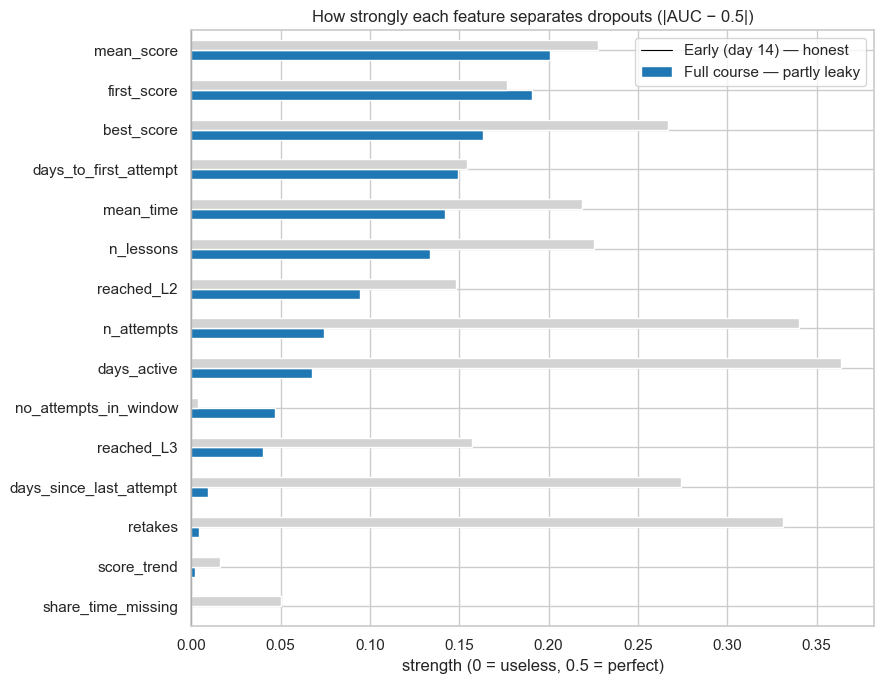

In [9]:
plot = signal[["early_strength", "full_strength"]].sort_values("early_strength")
plot.plot.barh(figsize=(9, 7), color=["tab:blue", "lightgrey"])
plt.axvline(0, color="black", lw=0.8)
plt.title("How strongly each feature separates dropouts (|AUC − 0.5|)")
plt.xlabel("strength (0 = useless, 0.5 = perfect)")
plt.legend(["Early (day 14) — honest", "Full course — partly leaky"])
plt.tight_layout()
plt.show()

**How to read this:**

- In the **full** set, the activity features (`days_active`, `n_attempts`, `retakes`, `days_since_last_attempt`) jump from
  weak to the strongest. They basically *describe* dropping out ("stopped showing up"), so there they're partly leaky.
- In the **early** set, the real signal is **quiz performance** (`mean_score`, `first_score`) and **how students work**
  (`mean_time`, `days_to_first_attempt`). Dropouts score ~11 points lower from their very first quiz, spend less time, and start sooner.
- `n_lessons` **flips direction**. Early on, trying *more* lessons means *higher* dropout risk (rushing ahead);
  over the full course it means lower risk (finishing). Same column, opposite story, and that's why the timing matters.

## 6. A closer look at the top early features

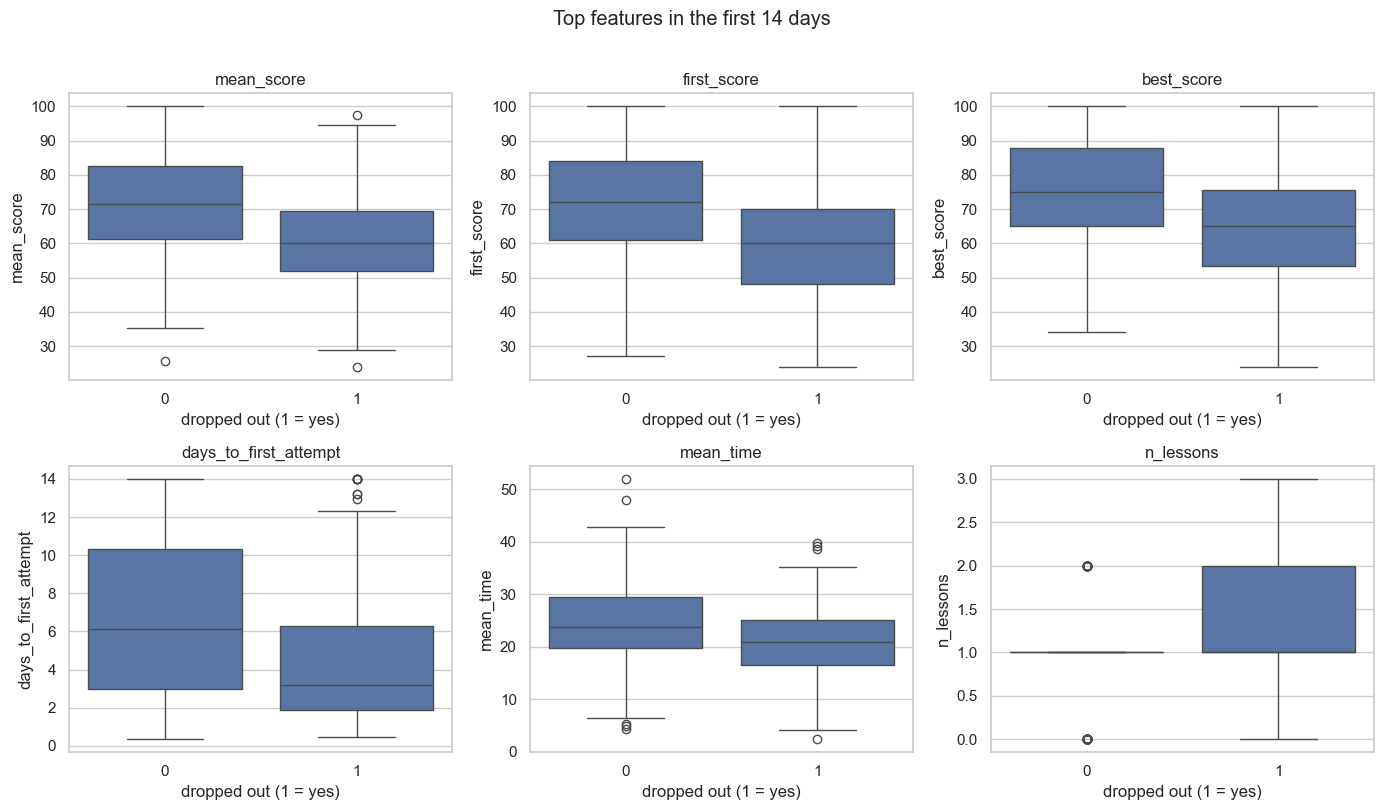

In [10]:
top = signal.sort_values("early_strength", ascending=False).index[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, top):
    sns.boxplot(data=early, x="dropped", y=col, ax=ax)
    ax.set(title=col, xlabel="dropped out (1 = yes)")
plt.suptitle(f"Top features in the first {WINDOW_DAYS} days", y=1.01)
plt.tight_layout()
plt.show()

In [11]:
early.groupby("dropped")[list(top)].mean().round(1).rename(index={0: "stayed", 1: "dropped"})

,mean_score,first_score,best_score,days_to_first_attempt,mean_time,n_lessons
dropped,,,,,,
stayed,71.8,72.1,75.2,6.9,24.6,0.9
dropped,60.9,60.7,65.5,4.6,20.8,1.3


## 7. Profile features

Dropout rate by category. These are the same in both sets (profile data doesn't change over time).

In [12]:
for col in ["device", "age_group", "country"]:
    rate = early.groupby(col)["dropped"].agg(students="count", dropout_rate="mean").round(2)
    display(rate.sort_values("dropout_rate", ascending=False))

,students,dropout_rate
device,,
unknown,16,0.44
mobile,269,0.28
tablet,54,0.22
desktop,161,0.20


,students,dropout_rate
age_group,,
45+,36,0.36
unknown,21,0.29
35-44,77,0.26
18-24,214,0.24
25-34,152,0.23


,students,dropout_rate
country,,
UAE,64,0.30
Bangladesh,48,0.29
India,303,0.24
Sri Lanka,50,0.24
Kenya,35,0.17


- `device = "unknown"` stands out (44%), which is why we kept missingness as its own category.
- `country` differences are small, and country can act as a proxy for income or region. **Fairness note:** we keep it
  in the file but will test whether the model actually needs it. If it doesn't help, we drop it.

## 8. Are any features near-copies of each other?

Highly correlated features (|r| > 0.8) tell the model the same thing twice. That's fine for trees,
but it makes logistic-regression coefficients hard to interpret.

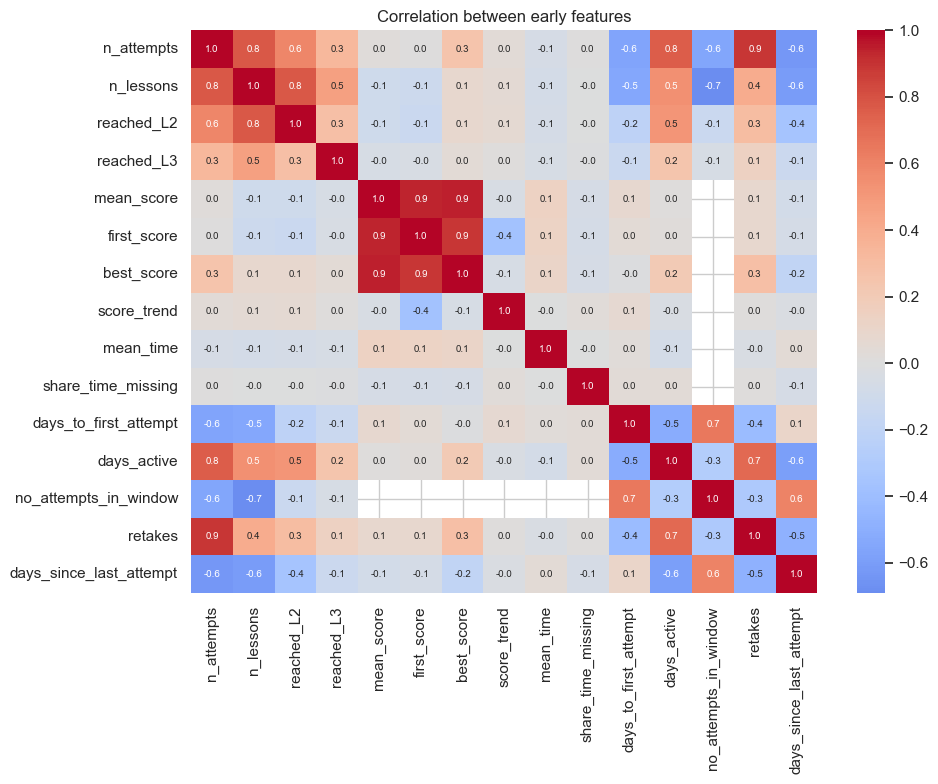

mean_score   best_score     0.95
             first_score    0.94
first_score  best_score     0.89
n_attempts   retakes        0.89
dtype: float64

In [13]:
corr = early[numeric].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation between early features")
plt.tight_layout()
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().loc[lambda s: s.abs() > 0.8].sort_values(key=abs, ascending=False))
pairs.round(2)

Expect the score features (`mean_score`, `first_score`, `best_score`) to move together, and the count features
(`n_attempts`, `n_lessons`, `retakes`) too. For the interpretable model we'll likely keep one from each group.

## 9. Save

In [14]:
early.to_csv(OUT / "features_early.csv", index=False)
full.to_csv(OUT / "features_full.csv", index=False)
signal.round(4).to_csv(OUT / "feature_signal.csv")

print("Saved to", OUT)
print(" features_early.csv  <- use this for the real model")
print(" features_full.csv   <- comparison only (partly leaky)")

Saved to D:\Claude\Crucifiers\Assistant\data\features
 features_early.csv  <- use this for the real model
 features_full.csv   <- comparison only (partly leaky)


## Summary

- **One row per student**, 500 rows. Students with no attempts get 0 counts plus a `no_attempts_in_window` flag.
- **Prediction moment = day 14 after signup.** Change `WINDOW_DAYS` at the top to try 7 or 21.
- **Main finding:** early on, dropouts don't do *fewer* quizzes. They **score lower, spend less time, and start faster**.
  Whole-course activity features look stronger only because they partly record the dropout itself.
- **Excluded:** `refund_requested` (leak), raw `signup_date` (calendar quirk). `country` is kept but under review for fairness.
- **Left for the model notebook:** imputing score/time NaNs and one-hot encoding the categories, both inside the CV pipeline.

**Next step:** baselines (majority class, one-rule) → logistic regression with 5-fold stratified CV on `features_early.csv`,
and the same model on `features_full.csv` + `refund_requested` to show how big the leak gap is.